# Facula transit, $\Delta T$ = 0-100 K with the Meunier or MURaM limb brightening (add_limb_brightening), MURaM and Phoenix spectra

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sunsim import *
from sunsim import local_path

T_QUIET, LOGG = 5778.0, 4.44                       # [K], [cgs]
DT_LIST = [0, 25, 50, 75, 100]                     # [K] added to the facula spectrum of each law
LAWS = ['Meunier', 'MURaM']                        # limb brightening of the facula before dT
SPECTRA = ['MURaM', 'Phoenix']
FACULA_RADIUS = 10.0                               # [deg], equator, longitude 180 deg
P_ROT = 25.05                                      # [days], rigid rotation, equator-on
TIMES = np.linspace(0, P_ROT, 181)
N_RINGS_PHOT, N_RINGS_CCF = 30, 30
RV_GRID = np.arange(-18000, 18025, 25)             # [m/s]
MASK = str(local_path('ccf_masks') / 'HARPS_G20_mps_friendly.mas')
BAND_PHOT = (3800, 8000)                           # [A] photometry, box; band of the MURaM law
BAND_CCF = (3790, 6810)                            # [A] Phoenix HiRes window and ring brightness of the Phoenix CCFs (mask 3801-6798 A)
PHOENIX = local_path('phoenix_models')             # HiRes/ and SPECINT/, 5600-6300 K, logg 4.0 and 4.5, [Fe/H] = 0
FIT_DEGREE = 3                                     # polynomial in mu of the MURaM dT law
COLORS = {dT: plt.cm.Oranges(0.3 + 0.65 * i / (len(DT_LIST) - 1)) for i, dT in enumerate(DT_LIST)}

## Limb brightening laws

MURaM law: dT(mu) = 66.7 mu^0 + 189.0 mu^1 + -552.6 mu^2 + 302.8 mu^3 K
fit residuals [K]: -2.6, 3.5, 2.1, -1.1, -2.6, -1.8, 0.3, 2.1, 1.9, -1.9


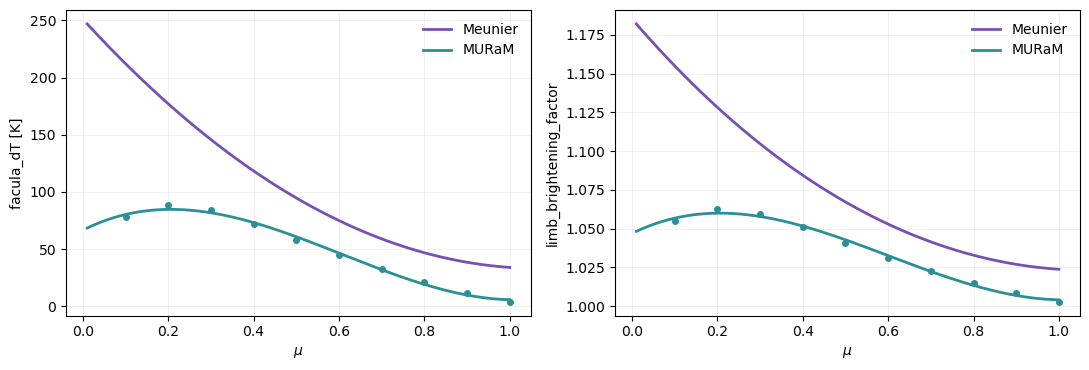

In [2]:
def load(key, name):
    return np.load(str(local_path(key) / name), allow_pickle=True).item()


muram_q = load('muram_spectra', 'av_solar_ssd_200G_10_mu_angles_PHOENIX_high_res_grid.npy')
muram_q_low = load('muram_lowres_spectra', 'av_solar_ssd_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')
muram_fc_low = load('muram_lowres_spectra', 'av_solar_faculae_200G_10_mu_angles_PHOENIX_low_res_specint_grid_cleaned.npy')


def band_intensity(d):
    w = np.asarray(d['wav'], dtype=np.float64)
    k = (w > BAND_PHOT[0]) & (w < BAND_PHOT[1])
    return np.asarray(d['intensity'], dtype=np.float64)[k].sum()


# MURaM law: dT(mu) = T [(I_fc / I_qp)^(1/4) - 1] of the MURaM spectra in BAND_PHOT, so that limb_brightening_factor = I_fc / I_qp;
# polynomial of degree FIT_DEGREE in mu (coefficients in increasing powers of mu, as FACULA_DT_LAWS)
MU_MURAM = np.array(sorted(float(m) for m in muram_q_low))
RATIO_MURAM = np.array([band_intensity(muram_fc_low[m]) / band_intensity(muram_q_low[m]) for m in sorted(muram_q_low, key=float)])
DT_MURAM = T_QUIET * (RATIO_MURAM**0.25 - 1)
MURAM_LAW = tuple(np.polynomial.Polynomial.fit(MU_MURAM, DT_MURAM, FIT_DEGREE).convert().coef)
LAW_ARG = {'Meunier': 'meunier', 'MURaM': MURAM_LAW}
print('MURaM law: dT(mu) = ' + ' + '.join('%.1f mu^%d' % (c, k) for k, c in enumerate(MURAM_LAW)) + ' K')
print('fit residuals [K]: ' + ', '.join('%.1f' % r for r in DT_MURAM - facula_dT(MU_MURAM, MURAM_LAW)))

mu_plot = np.linspace(0.01, 1, 200)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for law, c in zip(LAWS, ('#7a4fb3', '#2a8f96')):
    axes[0].plot(mu_plot, facula_dT(mu_plot, LAW_ARG[law]), color=c, lw=2, label=law)
    axes[1].plot(mu_plot, limb_brightening_factor(mu_plot, T_QUIET, LAW_ARG[law]), color=c, lw=2, label=law)
axes[0].plot(MU_MURAM, DT_MURAM, 'o', color='#2a8f96', ms=4)
axes[1].plot(MU_MURAM, RATIO_MURAM, 'o', color='#2a8f96', ms=4)
axes[0].set_ylabel(r'facula_dT [K]')
axes[1].set_ylabel(r'limb_brightening_factor')
for ax in axes:
    ax.set_xlabel(r'$\mu$')
    ax.grid(alpha=0.25, lw=0.5)
    ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## Spectra

In [3]:
def bb_ratio(w, dT):
    return black_body(w, T_QUIET + dT) / black_body(w, T_QUIET)


def hotter(flux, dT):
    """{mu: {'wav', 'intensity'}} x B(T_QUIET + dT) / B(T_QUIET)."""
    return {mu: {'wav': d['wav'], 'intensity': np.asarray(d['intensity'], dtype=np.float64) * bb_ratio(d['wav'], dT)}
            for mu, d in flux.items()}


def muram_facula(law, dT, low):
    """add_limb_brightening(MURaM quiet x B(T + dT) / B(T), T, law)."""
    return add_limb_brightening(hotter(muram_q_low if low else muram_q, dT), T_QUIET, LAW_ARG[law])


def phoenix_facula(law, dT, low):
    """Photometry: add_limb_brightening(Phoenix SPECINT at T + dT, T, law); CCF: Phoenix HiRes at T + dT (brightness of the
    rings, with the law, from mu_ratio)."""
    if low:
        return add_limb_brightening(interpolate_phoenix_mu(PHOENIX / 'SPECINT', T_QUIET + dT, LOGG, 0.0, *BAND_PHOT,
                                                           mu_angles=phx_q_low), T_QUIET, LAW_ARG[law])
    return interpolate_phoenix(PHOENIX / 'HiRes', T_QUIET + dT, LOGG, 0.0, *BAND_CCF)


phx_q_low = interpolate_phoenix_mu(PHOENIX / 'SPECINT', T_QUIET, LOGG, 0.0, *BAND_PHOT)
quiet = {('MURaM', True): muram_q_low, ('MURaM', False): muram_q,
         ('Phoenix', True): phx_q_low, ('Phoenix', False): interpolate_phoenix(PHOENIX / 'HiRes', T_QUIET, LOGG, 0.0, *BAND_CCF)}
facula = {'MURaM': muram_facula, 'Phoenix': phoenix_facula}

## Grids

In [4]:
def phot_grid(flux, typ, band=BAND_PHOT, n_rings=N_RINGS_PHOT):
    g = flux_grid(n_rings, flux, typ, None, *band, rotation_period=P_ROT, inclination=0,
                  stellar_rotation=False, mode='photometry')
    g.built_grid()
    return g


wvm, fm = mask_weights(MASK)


def ring_brightness(flux_low, typ):
    """Brightness of one cell of every ring in BAND_CCF, for the mu_ratio of the Phoenix CCFs."""
    g = phot_grid(flux_low, typ, BAND_CCF, N_RINGS_CCF)
    return g.grid / (g.parea / (4 * np.pi))


b_ref = ring_brightness(phx_q_low, 'quiet').max()


def ccf_grid(spec, flux, flux_low, typ):
    if spec == 'MURaM':
        g = CCF_grid(N_RINGS_CCF, flux, RV_GRID, wvm, fm, convective_blueshift=0, phoenix_resolution=True, normalization='none')
    else:
        g = CCF_grid(N_RINGS_CCF, flux, RV_GRID, wvm, fm, convective_blueshift=0, phoenix_resolution=True,
                     mu_ratio=ring_brightness(flux_low, typ) / b_ref, normalization=False)
    g.built_grid(bisector=None)
    return g


phot, ccf = {}, {}
for spec in SPECTRA:
    phot[spec, 'quiet'] = phot_grid(quiet[spec, True], 'quiet').grid
    ccf[spec, 'quiet'] = ccf_grid(spec, quiet[spec, False], quiet[spec, True], 'quiet')
    for law in LAWS:
        for dT in DT_LIST:
            low = facula[spec](law, dT, True)
            phot[spec, law, dT] = phot_grid(low, 'fc').grid
            ccf[spec, law, dT] = ccf_grid(spec, facula[spec](law, dT, False), low, 'fc')

OMP: Info #276: omp_set_nested routine deprecated, please use omp_set_max_active_levels instead.


## Transits

In [5]:
region = [active_region('fc', FACULA_RADIUS, 90, 180)]
cmd = (TIMES - P_ROT / 2) / P_ROT * 360            # [deg] longitude from the central meridian
runs = {}
for spec in SPECTRA:
    for law in LAWS:
        for dT in DT_LIST:
            ss = StarSim(TIMES, N_RINGS_CCF, inclination=0, rotation_period=P_ROT, active_regions_map=region,
                         mode=['photometry', 'ccf'], flux_grid_qp=phot[spec, 'quiet'], flux_grid_sp=phot[spec, 'quiet'],
                         flux_grid_fc=phot[spec, law, dT], ccf_grid_qp=ccf[spec, 'quiet'], ccf_grid_sp=ccf[spec, 'quiet'],
                         ccf_grid_fc=ccf[spec, law, dT])
            ss.generate_timeseries(verbose=False)
            assert ss.ff_fc[0] == 0
            runs[spec, law, dT] = ss

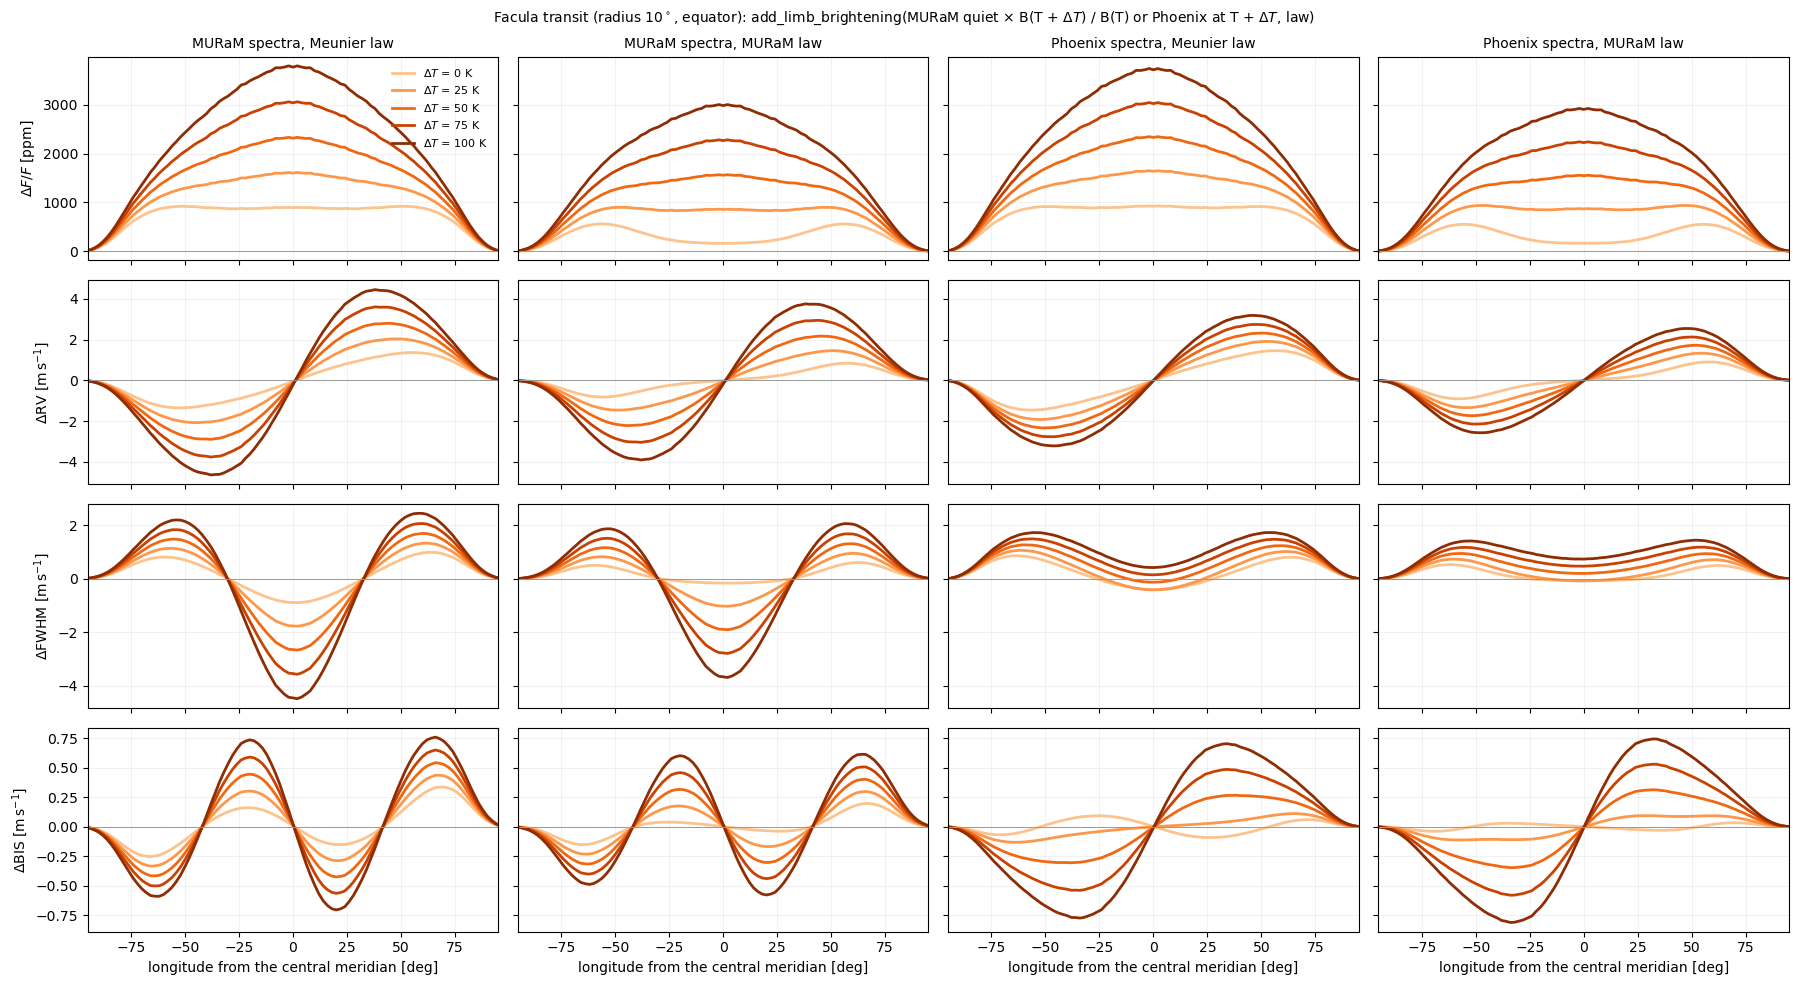

In [6]:
LABELS = {'flux': r'$\Delta F / F$ [ppm]', 'rv': r'$\Delta$RV [m$\,$s$^{-1}$]', 'fwhm': r'$\Delta$FWHM [m$\,$s$^{-1}$]',
          'bis': r'$\Delta$BIS [m$\,$s$^{-1}$]'}
COLUMNS = [(spec, law) for spec in SPECTRA for law in LAWS]
fig, axes = plt.subplots(len(LABELS), len(COLUMNS), figsize=(18, 10), sharex=True, sharey='row')
for j, (spec, law) in enumerate(COLUMNS):
    for dT in DT_LIST:
        ss = runs[spec, law, dT]
        series = {'flux': (ss.flux_var / ss.flux_var[0] - 1) * 1e6, 'rv': ss.rv_var - ss.rv_var[0],
                  'fwhm': ss.fwhm_var - ss.fwhm_var[0], 'bis': ss.bis_var - ss.bis_var[0]}
        on = ss.ff_fc > 0
        for ax, q in zip(axes[:, j], LABELS):
            ax.plot(cmd[on], series[q][on], lw=2, color=COLORS[dT], label=r'$\Delta T$ = %d K' % dT)
    axes[0, j].set_title('%s spectra, %s law' % (spec, law), fontsize=10)
    axes[-1, j].set_xlabel('longitude from the central meridian [deg]')
for ax, q in zip(axes[:, 0], LABELS):
    ax.set_ylabel(LABELS[q])
for ax in axes.ravel():
    ax.axhline(0, color='0.6', lw=0.7)
    ax.grid(alpha=0.25, lw=0.5)
axes[0, 0].legend(frameon=False, fontsize=8)
axes[-1, 0].set_xlim(-95, 95)
fig.suptitle(r'Facula transit (radius %g$^\circ$, equator): add_limb_brightening(MURaM quiet $\times$ B(T + $\Delta T$) / B(T) or Phoenix at T + $\Delta T$, law)' % FACULA_RADIUS, fontsize=10)
plt.tight_layout()
plt.show()

In [7]:
# amplitudes over the transit (max - min)
for spec, law in COLUMNS:
    for dT in DT_LIST:
        ss = runs[spec, law, dT]
        on = ss.ff_fc > 0
        amp = lambda x: np.ptp(x[on])
        print('%-7s %-7s %3d K  flux %6.0f ppm   RV %5.2f   FWHM %5.2f   BIS %5.2f m/s'
              % (spec, law, dT, amp(ss.flux_var / ss.flux_var[0] * 1e6), amp(ss.rv_var), amp(ss.fwhm_var), amp(ss.bis_var)))

MURaM   Meunier   0 K  flux    921 ppm   RV  2.72   FWHM  1.88   BIS  0.59 m/s
MURaM   Meunier  25 K  flux   1612 ppm   RV  4.11   FWHM  3.11   BIS  0.77 m/s
MURaM   Meunier  50 K  flux   2333 ppm   RV  5.71   FWHM  4.36   BIS  0.97 m/s
MURaM   Meunier  75 K  flux   3062 ppm   RV  7.38   FWHM  5.63   BIS  1.21 m/s
MURaM   Meunier 100 K  flux   3798 ppm   RV  9.11   FWHM  6.92   BIS  1.46 m/s
MURaM   MURaM     0 K  flux    559 ppm   RV  1.66   FWHM  0.77   BIS  0.35 m/s
MURaM   MURaM    25 K  flux    900 ppm   RV  2.92   FWHM  1.98   BIS  0.53 m/s
MURaM   MURaM    50 K  flux   1568 ppm   RV  4.40   FWHM  3.21   BIS  0.72 m/s
MURaM   MURaM    75 K  flux   2283 ppm   RV  6.00   FWHM  4.47   BIS  0.95 m/s
MURaM   MURaM   100 K  flux   3005 ppm   RV  7.68   FWHM  5.74   BIS  1.19 m/s
Phoenix Meunier   0 K  flux    928 ppm   RV  2.92   FWHM  1.27   BIS  0.18 m/s
Phoenix Meunier  25 K  flux   1650 ppm   RV  3.84   FWHM  1.47   BIS  0.24 m/s
Phoenix Meunier  50 K  flux   2349 ppm   RV  4.66   